[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/09_probability.ipynb)

*Math for Data Science & ML · Notebook 9 of 10*

# Probability

Measuring uncertainty: counting outcomes, permutations and combinations, the rules of probability, conditional probability, Bayes' theorem, independence and expected value.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Probability is a precise way to count how surprised you should be. Bayes' rule updates a belief as evidence arrives.

**What interviewers really test here:** Conditional probability, Bayes' rule and expected value puzzles.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What is probability? *(Basics)*
- [ ] 2. Counting: permutations and combinations *(Basics)*
- [ ] 3. List the outcomes first *(Basics)*
- [ ] 4. Combining events: and, or, conditional *(Core)*
- [ ] 5. Bayes' theorem: updating beliefs *(Core)*
- [ ] 6. Counting, worked *(Core)*
- [ ] 7. Conditional probability with a table *(Core)*
- [ ] 8. Random variables and expected value *(Advanced)*
- [ ] 9. Bayes: updating step by step *(Advanced)*
- [ ] 10. Expected value for decisions *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Axioms and basic rules

A probability P assigns a number to every event with: (1) P(A) ≥ 0, (2) P(sample space) = 1, (3) for mutually exclusive events P(A ∪ B) = P(A) + P(B). Everything else follows:




- P(∅) = 0, P(Aᶜ) = 1 − P(A), 0 ≤ P(A) ≤ 1.
- Inclusion–exclusion: P(A ∪ B) = P(A) + P(B) − P(A ∩ B).
- Interpretations: **classical** (equally likely outcomes), **frequentist** (long-run frequency), **Bayesian** (degree of belief).

### Counting

|   | Order matters | Order doesn't matter |
| --- | --- | --- |
| Without repetition | P(n, k) = n!/(n − k)! | C(n, k) = n!/(k!(n − k)!) |
| With repetition | nᵏ | C(n + k − 1, k) |



Multinomial: arrangements of n items with groups of sizes k₁, k₂, … = n!/(k₁!k₂!…). Pascal's rule C(n, k) = C(n − 1, k − 1) + C(n − 1, k).

### Conditional probability, independence and Bayes

- P(A | B) = P(A ∩ B)/P(B), for P(B) &gt; 0.
- Chain rule: P(A ∩ B ∩ C) = P(A)·P(B | A)·P(C | A ∩ B).
- Independence: P(A ∩ B) = P(A)P(B) ⇔ P(A | B) = P(A). Independent ≠ mutually exclusive (exclusive events with positive probability are dependent).
- Law of total probability: P(B) = Σᵢ P(B | Aᵢ)P(Aᵢ) for a partition A₁, A₂, ….
- **Bayes**: P(A | B) = P(B | A)P(A)/P(B). Vocabulary: P(A) prior, P(B | A) likelihood, P(A | B) posterior, P(B) evidence.
- Base-rate fallacy: ignoring a small prior makes a positive test seem far more conclusive than it is.

### Random variables

<table> <tr><th></th><th>Discrete</th><th>Continuous</th></tr> <tr><td>Described by</td><td>PMF p(x) = P(X = x)</td><td>PDF f(x); P(a ≤ X ≤ b) = ∫ₐᵇ f</td></tr> <tr><td>CDF</td><td colspan="2">F(x) = P(X ≤ x), rises from 0 to 1</td></tr> <tr><td>E[X]</td><td>Σ x p(x)</td><td>∫ x f(x) dx</td></tr> </table>




- Linearity: E[aX + bY] = aE[X] + bE[Y] (always, even if dependent).
- Var(aX + b) = a²Var(X); for independent X, Y: Var(X + Y) = Var X + Var Y.
- Covariance Cov(X, Y) = E[XY] − E[X]E[Y]; independence ⇒ Cov = 0 (not the reverse).

---
# Part 2: Lessons, step by step

## Lesson 1: What is probability?

*Level: Basics*

**Probability** is a number from 0 to 1 measuring how likely something is: 0 = impossible, 1 = certain, 0.5 = a coin flip.




- An **experiment** (rolling a die) has **outcomes** (1 … 6). All possible outcomes form the **sample space**.
- An **event** is a set of outcomes ("an even number" = {2, 4, 6}).
- When outcomes are equally likely: **P(event) = favourable outcomes / total outcomes**. P(even) = 3/6 = 0.5.
- **Complement**: P(not A) = 1 − P(A). Often the easy way round: P(at least one six in 4 rolls) = 1 − (5/6)⁴.



A classifier that outputs "spam: 0.93" is giving a probability.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

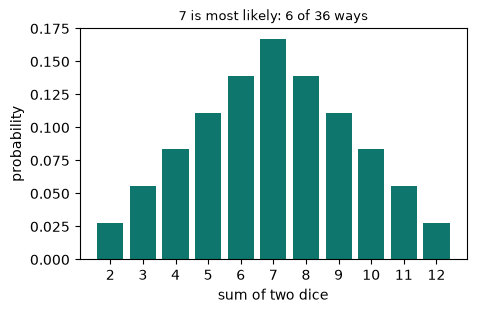

In [2]:
def two_dice():
    sums = np.add.outer(np.arange(1, 7), np.arange(1, 7))
    totals, counts = np.unique(sums, return_counts=True)
    probs = counts / 36
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(totals, probs, color="#0f766e")
    ax.set_xticks(totals)
    ax.set_xlabel("sum of two dice")
    ax.set_ylabel("probability")
    ax.set_title("7 is most likely: 6 of 36 ways", fontsize=9)


two_dice()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 2: Counting: permutations and combinations

*Level: Basics*

Probabilities often need you to count outcomes without listing them all.




- **Multiplication principle**: 3 shirts × 4 trousers = 12 outfits.
- **Permutations** (order matters): choosing gold/silver/bronze from 10 runners: 10·9·8 = 720 = n!/(n − k)!.
- **Combinations** (order doesn't matter): choosing a 3-person team from 10: 720/3! = 120 = C(10, 3) = n!/(k!(n − k)!).
- Repeated items: BANANA has 6!/(3!·2!) = 60 arrangements.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def pascal():
    rows = [[1]]
    for _ in range(6):
        prev = rows[-1]
        rows.append([1] + [prev[i] + prev[i + 1] for i in range(len(prev) - 1)] + [1])
    check = math.comb(6, 2)


pascal()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q11](#q11), [Q16](#q16), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 3: List the outcomes first

*Level: Basics*

Most probability mistakes come from not listing what can happen.



#### Two coins: P(at least one head)?



A tempting answer: "0, 1 or 2 heads, so 2 out of 3". But those three aren't equally likely. List properly:



| Outcome | HH | HT | TH | TT |
| --- | --- | --- | --- | --- |
| Probability | 1/4 | 1/4 | 1/4 | 1/4 |



Three of the four have a head, so **P = 3/4**.



#### Using a probability tree



Multiply along branches, add across paths. For two flips, P(exactly one head) = ½·½ + ½·½ = ½.



#### Helpful checks



- All probabilities must add to 1.
- "At least one" is usually easiest as 1 − P(none).
- Results always lie between 0 and 1.



#### The gambler's fallacy



After 5 heads in a row, the next flip is still 50/50. Coins have no memory. A run of bad luck doesn't make good luck "due".

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def coins_listing():
    from itertools import product
    outcomes = list(product("HT", repeat=2))
    with_a_head = [o for o in outcomes if "H" in o]
    probability = len(with_a_head) / len(outcomes)
    exactly_one = sum(o.count("H") == 1 for o in outcomes) / len(outcomes)
    three_flips = 1 - 0.5 ** 3


coins_listing()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 4: Combining events: and, or, conditional

*Level: Core*

| Rule | Formula |
| --- | --- |
| Or (addition) | P(A or B) = P(A) + P(B) − P(A and B) |
| And (multiplication) | P(A and B) = P(A) · P(B \| A) |
| Independent | P(A and B) = P(A) · P(B) |
| Conditional | P(A \| B) = P(A and B) / P(B) |



**P(A | B)** reads "probability of A **given** B": shrink your world to only the cases where B happened. From a table of counts, divide the cell by its row or column total.



Independence means knowing B tells you nothing about A (two coin flips). Drawing cards **without replacement** is not independent: the first draw changes the second.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def contingency():
    table = np.array([[30, 10], [20, 40]])
    total = table.sum()
    p_row0 = table[0].sum() / total
    p_col0 = table[:, 0].sum() / total
    p_row0_given_col0 = table[0, 0] / table[:, 0].sum()
    p_both = table[0, 0] / total
    independent = np.isclose(p_both, p_row0 * p_col0)


contingency()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q10](#q10), [Q8](#q8), [Q17](#q17), [Q9](#q9), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 5: Bayes' theorem: updating beliefs

*Level: Core*

Bayes' theorem flips a conditional probability around:



**P(A | B) = P(B | A) · P(A) / P(B)**



Classic example: a disease affects 1% of people; a test catches 99% of cases but also flags 5% of healthy people. If you test positive, how worried should you be? Picture 10 000 people: 100 sick → 99 test positive; 9 900 healthy → 495 test positive. Of 594 positives only 99 are sick: **about 17%**. The rare **prior** dominates.



The **Naive Bayes** classifier applies Bayes to every word of an email and multiplies the evidence — fast, simple and still used for spam filtering.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

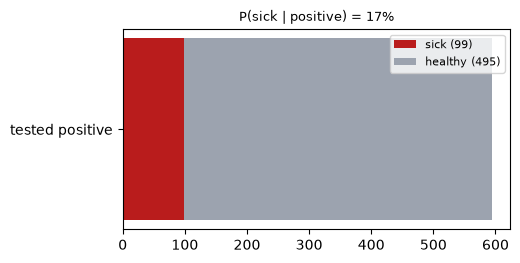

In [6]:
def bayes_picture():
    people = 10000
    sick = people * 0.01
    healthy = people - sick
    true_pos = sick * 0.99
    false_pos = healthy * 0.05
    p_sick_given_pos = true_pos / (true_pos + false_pos)
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.barh(["tested positive"], [true_pos], color="#b91c1c", label=f"sick ({true_pos:.0f})")
    ax.barh(["tested positive"], [false_pos], left=[true_pos], color="#9ca3af", label=f"healthy ({false_pos:.0f})")
    ax.legend(fontsize=8)
    ax.set_title(f"P(sick | positive) = {p_sick_given_pos:.0%}", fontsize=9)


bayes_picture()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q20](#q20), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: Counting, worked

*Level: Core*

Ask two questions: **does order matter?** and **can things repeat?**



| Question | Order? | Repeats? | Calculation | Answer |
| --- | --- | --- | --- | --- |
| 4-digit PINs | yes | yes | 10⁴ | 10,000 |
| 4-digit PINs with no repeats | yes | no | 10·9·8·7 | 5,040 |
| Team of 3 from 10 | no | no | (10·9·8) / 3! | 120 |



**Why divide by 3!?** Each team of Ana, Ben, Cy was counted in 6 orders: ABC, ACB, BAC, BCA, CAB, CBA.



#### Using counts to get a probability



Two cards from a deck. P(both aces)?



- Ways to choose 2 aces: C(4, 2) = 6.
- Ways to choose any 2 cards: C(52, 2) = 1,326.
- P = 6 / 1326 = **0.0045**.



Step by step gives the same: (4/52) × (3/51) = 0.0045. Pick whichever seems easier.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def counting_checks():
    pins = 10 ** 4
    no_repeats = math.perm(10, 4)
    teams = math.comb(10, 3)
    orders_of_a_team = math.factorial(3)
    by_counting = math.comb(4, 2) / math.comb(52, 2)
    step_by_step = (4 / 52) * (3 / 51)


counting_checks()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q11](#q11), [Q16](#q16), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 7: Conditional probability with a table

*Level: Core*

100 people:



|   | Smoker | Non-smoker | Total |
| --- | --- | --- | --- |
| Cough | 30 | 10 | 40 |
| No cough | 20 | 40 | 60 |
| Total | 50 | 50 | 100 |



Conditioning means **shrinking your world to one row or column.**



| Question | Look only at | Answer |
| --- | --- | --- |
| P(cough \| smoker) | smokers: 50 people | 30 / 50 = 0.6 |
| P(smoker \| cough) | coughers: 40 people | 30 / 40 = 0.75 |
| P(cough) | everyone | 40 / 100 = 0.4 |
| P(cough and smoker) | everyone | 30 / 100 = 0.3 |



#### The biggest confusion



**P(A | B) isn't P(B | A).** Nearly all cats have four legs, but few four-legged animals are cats.



#### Independent?



Smoking and coughing would be independent if P(cough | smoker) equalled P(cough). Here 0.6 ≠ 0.4, so they're related. **Related doesn't prove one causes the other.**

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def table_conditioning():
    table = np.array([[30, 10], [20, 40]])
    cough_given_smoker = table[0, 0] / table[:, 0].sum()
    smoker_given_cough = table[0, 0] / table[0].sum()
    cough = table[0].sum() / table.sum()
    both = table[0, 0] / table.sum()
    expected_if_independent = cough * (table[:, 0].sum() / table.sum())


table_conditioning()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q17](#q17), [Q9](#q9), [Q10](#q10), [Q8](#q8), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 8: Random variables and expected value

*Level: Advanced*

A **random variable** X assigns a number to each outcome (the value of a die, your winnings in a game). Its **distribution** lists each value with its probability.




- **Expected value** E[X] = Σ x·P(x): the long-run average. A die: 3.5.
- **Variance** Var(X) = E[(X − μ)²] = E[X²] − (E[X])²: how spread out the outcomes are. Its square root is the standard deviation.
- Waiting for a success with chance p takes 1/p tries on average.



ML models are often judged by **expected loss** — the average error over all the data they might see.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

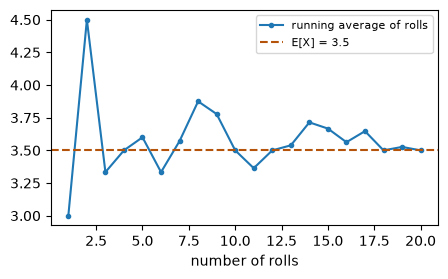

In [9]:
def expected_value_demo():
    values = np.arange(1, 7)
    probs = np.full(6, 1 / 6)
    mean = values @ probs
    variance = probs @ (values - mean) ** 2
    running = np.cumsum([3, 6, 1, 4, 4, 2, 5, 6, 3, 1, 2, 5, 4, 6, 3, 2, 5, 1, 4, 3]) / np.arange(1, 21)
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(np.arange(1, 21), running, "o-", markersize=3, label="running average of rolls")
    ax.axhline(mean, color="#b45309", linestyle="--", label="E[X] = 3.5")
    ax.legend(fontsize=8)
    ax.set_xlabel("number of rolls")


expected_value_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 9: Bayes: updating step by step

*Level: Advanced*

Recall the test: 1% have the disease, it detects 99% of cases, and flags 5% of healthy people. One positive result means a **16.7%** chance of disease.



#### A second positive test



Today's answer becomes tomorrow's prior. Now start from 0.167:



P = (0.99 × 0.167) / (0.99 × 0.167 + 0.05 × 0.833) = **0.798**.



Two independent positive tests take us from 1% to about 80%. That's Bayesian updating.



#### The prior matters enormously



| How common is it? | 0.1% | 1% | 10% | 50% |
| --- | --- | --- | --- | --- |
| P(disease \| positive) | 1.9% | 16.7% | 68.8% | 95.2% |



The same test gives very different meanings. This is why screening for rare conditions gives many false alarms, and why a rare-class classifier can have high accuracy but low precision.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

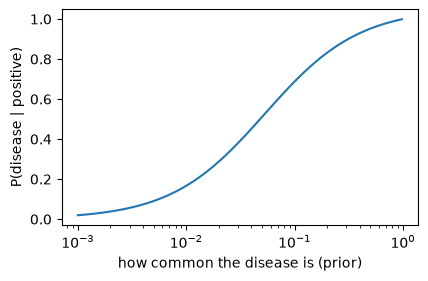

In [10]:
def bayes_updates():
    def update(prior, sensitivity=0.99, false_alarm=0.05):
        return sensitivity * prior / (sensitivity * prior + false_alarm * (1 - prior))

    first = update(0.01)
    second = update(first)
    priors = np.logspace(-3, -0.01, 100)
    posteriors = update(priors)
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    ax.semilogx(priors, posteriors)
    ax.set_xlabel("how common the disease is (prior)")
    ax.set_ylabel("P(disease | positive)")


bayes_updates()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. update() returns 0.16666666666666669
2. update() returns 0.7983870967741936
3. update() returns array([0.01943463, 0.02080662, 0.0222...
4. bayes\_updates() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q20](#q20), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 10: Expected value for decisions

*Level: Advanced*

#### Is this ticket worth it?



A ₹10 ticket gives a 1 in 200 chance of ₹1,000. E[winnings] = 1000 × 1/200 = ₹5. Subtract the cost: **−₹5 per ticket on average**.



#### Expected values simply add



E[X + Y] = E[X] + E[Y], **even when they're related**. Two dice: 3.5 + 3.5 = 7. This makes hard-looking problems easy.



**Example:** shuffle n name-tags and hand them out. On average, how many people get their own? Each person has a 1/n chance, so the total is n × 1/n = **1**, for any n.



#### Variance adds only if independent



One die has variance 2.92, and two independent dice 5.83.



#### Expected cost in ML



If a missed fraud costs ₹5,000 and a false alarm ₹50, flag when P(fraud) × 5000 &gt; (1 − P(fraud)) × 50, or P(fraud) &gt; about 0.0099. The threshold comes from the costs, not from 0.5.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
def expected_checks():
    ticket = 1000 * (1 / 200) - 10
    r = np.random.default_rng(0)
    own_tags = [(r.permutation(10) == np.arange(10)).sum() for _ in range(5000)]
    average_fixed = float(np.mean(own_tags))
    two_dice = r.integers(1, 7, (20000, 2)).sum(axis=1)
    mean_var = (round(float(two_dice.mean()), 2), round(float(two_dice.var()), 2))
    threshold = 50 / (5000 + 50)


expected_checks()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [12]:
from itertools import product, permutations


<a id="q1"></a>
### Q1. Rolling a Total With Two Dice

🟢 Warm-up · *Count the outcomes*

Return the probability that two fair dice add up to k, rounded to 4 decimals.

**Examples**

- `k = 7` → `0.1667`
- `k = 2` → `0.0278`
- `k = 12` → `0.0278`

In [ ]:
def dice_total(k):
    """
    Return the probability that two fair dice add up to k, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dice_total, [
    ((7,), 0.1667),
    ((2,), 0.0278),
    ((12,), 0.0278),
    ((13,), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

List all 36 equally likely pairs and count the ones that add to k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Build the 6 × 6 table of sums with `np.add.outer` and take the mean of (table == k).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** List all 36 equally likely pairs and count the ones that add to k.

```python
def dice_total(k):
    favourable = 0
    total = 0
    for a in range(1, 7):
        for b in range(1, 7):
            total += 1
            if a + b == k:
                favourable += 1
    return round(favourable / total, 4)
```

**Cost:** O(36) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Build the 6 × 6 table of sums with `np.add.outer` and take the mean of (table == k).

```python
def dice_total(k):
    sums = np.add.outer(np.arange(1, 7), np.arange(1, 7))
    return round((sums == k).mean(), 4)
```

**Cost:** O(36) time, O(36) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: List all 36 equally likely pairs and count the ones that add to k. That costs O(36) time and O(1) space."

"I can do better: Build the 6 × 6 table of sums with `np.add.outer` and take the mean of (table == k). That's O(36) time and O(36) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/rolling-a-total-with-two-dice)

<a id="q2"></a>
### Q2. At Least One Six

🟢 Warm-up · *The complement rule*

Return the probability of at least one six in n rolls of a die, rounded to 4 decimals.

**Examples**

- `n = 1` → `0.1667`
- `n = 2` → `0.3056`
- `n = 4` → `0.5177`

In [ ]:
def at_least_one_six(n):
    """
    Return the probability of at least one six in n rolls of a die, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(at_least_one_six, [
    ((1,), 0.1667),
    ((2,), 0.3056),
    ((4,), 0.5177),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Enumerate all 6ⁿ sequences and count those containing a 6.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

1 − P(no six at all) = 1 − (5/6)ⁿ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Enumerate all 6ⁿ sequences and count those containing a 6.

```python
def at_least_one_six(n):
    hits = total = 0
    for rolls in product(range(1, 7), repeat=n):
        total += 1
        if 6 in rolls:
            hits += 1
    return round(hits / total, 4)
```

**Cost:** O(6ⁿ · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** 1 − P(no six at all) = 1 − (5/6)ⁿ.

```python
def at_least_one_six(n):
    return round(1 - (5 / 6) ** n, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Enumerate all 6ⁿ sequences and count those containing a 6. That costs O(6ⁿ · n) time and O(n) space."

"I can do better: 1 − P(no six at all) = 1 − (5/6)ⁿ. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/at-least-one-six)

<a id="q3"></a>
### Q3. Permutations

🟢 Warm-up · *Order matters: n!/(n − k)!*

Return the number of ways to arrange k items chosen from n (e.g. gold, silver, bronze from 10 runners).

**Examples**

- `n = 5, k = 2` → `20`
- `n = 10, k = 3` → `720`
- `n = 4, k = 4` → `24`

In [ ]:
def permutations_count(n, k):
    """
    Return the number of ways to arrange k items chosen from n (e.g. gold,
    silver, bronze from 10 runners).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(permutations_count, [
    ((5, 2), 20),
    ((10, 3), 720),
    ((4, 4), 24),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply n · (n − 1) · … for k factors: n choices for first place, n − 1 for second, …

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.perm(n, k)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply n · (n − 1) · … for k factors: n choices for first place, n − 1 for second, …

```python
def permutations_count(n, k):
    ways = 1
    for i in range(k):
        ways *= n - i
    return ways
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.perm(n, k)`.

```python
def permutations_count(n, k):
    return math.perm(n, k)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply n · (n − 1) · … for k factors: n choices for first place, n − 1 for second, … That costs O(k) time and O(1) space."

"I can do better: `math.perm(n, k)`. That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/permutations)

<a id="q4"></a>
### Q4. Combinations

🟢 Warm-up · *Order doesn't matter: n choose k*

Return the number of ways to choose k items from n when order does not matter.

**Examples**

- `n = 5, k = 2` → `10`
- `n = 10, k = 3` → `120`
- `n = 6, k = 0` → `1`

In [ ]:
def combinations_count(n, k):
    """
    Return the number of ways to choose k items from n when order does not
    matter.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(combinations_count, [
    ((5, 2), 10),
    ((10, 3), 120),
    ((6, 0), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pascal's triangle: build rows by adding the two numbers above.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.comb(n, k)` = n! / (k!(n − k)!).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Pascal's triangle: build rows by adding the two numbers above.

```python
def combinations_count(n, k):
    row = [1]
    for _ in range(n):
        row = [1] + [row[i] + row[i + 1] for i in range(len(row) - 1)] + [1]
    return row[k]
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `math.comb(n, k)` = n! / (k!(n − k)!).

```python
def combinations_count(n, k):
    return math.comb(n, k)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pascal's triangle: build rows by adding the two numbers above. That costs O(n·k) time and O(k) space."

"I can do better: `math.comb(n, k)` = n! / (k!(n − k)!). That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/combinations)

<a id="q5"></a>
### Q5. Drawing a Card: Or

🟢 Warm-up · *Addition rule*

From a standard 52-card deck, return P(card is a heart OR a king), rounded to 4 decimals.

**Examples**

- `` → `0.3077`

In [ ]:
def heart_or_king():
    """
    From a standard 52-card deck, return P(card is a heart OR a king), rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(heart_or_king, [
    ((), 0.3077),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build all 52 cards and count those that are hearts or kings.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

P(A) + P(B) − P(A and B) = 13/52 + 4/52 − 1/52.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Build all 52 cards and count those that are hearts or kings.

```python
def heart_or_king():
    ranks = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K"]
    suits = ["hearts", "diamonds", "clubs", "spades"]
    count = 0
    for r in ranks:
        for s in suits:
            if s == "hearts" or r == "K":
                count += 1
    return round(count / 52, 4)
```

**Cost:** O(52) time, O(52) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** P(A) + P(B) − P(A and B) = 13/52 + 4/52 − 1/52.

```python
def heart_or_king():
    return round(13 / 52 + 4 / 52 - 1 / 52, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build all 52 cards and count those that are hearts or kings. That costs O(52) time and O(52) space."

"I can do better: P(A) + P(B) − P(A and B) = 13/52 + 4/52 − 1/52. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/drawing-a-card-or)

<a id="q6"></a>
### Q6. Law of Total Probability

🟢 Warm-up · *Weighted average over cases*

Factories make shares[i] of the products with defect rates rates[i]. Return the overall defect rate, rounded to 4 decimals.

**Examples**

- `shares = [0.5, 0.3, 0.2], rates = [0.1, 0.2, 0.5]` → `0.21`
- `shares = [1.0], rates = [0.03]` → `0.03`

In [ ]:
def total_probability(shares, rates):
    """
    Factories make shares[i] of the products with defect rates rates[i]. Return
    the overall defect rate, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(total_probability, [
    (([0.5, 0.3, 0.2], [0.1, 0.2, 0.5]), 0.21),
    (([1.0], [0.03]), 0.03),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: add share × rate for each factory.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dot product: `shares @ rates`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: add share × rate for each factory.

```python
def total_probability(shares, rates):
    total = 0
    for s, r in zip(shares, rates):
        total += s * r
    return round(total, 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** A dot product: `shares @ rates`.

```python
def total_probability(shares, rates):
    return round(np.array(shares) @ np.array(rates), 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: add share × rate for each factory. That costs O(k) time and O(1) space."

"I can do better: A dot product: `shares @ rates`. That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/law-of-total-probability)

<a id="q7"></a>
### Q7. Expected Value

🟢 Warm-up · *E[X] = Σ x·P(x)*

Return the expected value of a random variable with the given values and probabilities, rounded to 4 decimals.

**Examples**

- `values = [1, 2, 3, 4, 5, 6], probs = [0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666]` → `3.5`
- `values = [0, 100], probs = [0.9, 0.1]` → `10.0`
- `values = [-5, 20], probs = [0.8, 0.2]` → `0.0`

In [ ]:
def expected(values, probs):
    """
    Return the expected value of a random variable with the given values and
    probabilities, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expected, [
    (([1, 2, 3, 4, 5, 6], [0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666]), 3.5),
    (([0, 100], [0.9, 0.1]), 10.0),
    (([-5, 20], [0.8, 0.2]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: add value × probability.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.dot(values, probs)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: add value × probability.

```python
def expected(values, probs):
    total = 0
    for v, p in zip(values, probs):
        total += v * p
    return round(total, 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.dot(values, probs)`.

```python
def expected(values, probs):
    return round(np.dot(values, probs), 4) + 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: add value × probability. That costs O(n) time and O(1) space."

"I can do better: `np.dot(values, probs)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/expected-value)

<a id="q8"></a>
### Q8. All Parts Must Work

🟢 Warm-up · *Independent events multiply*

A machine works only if every part works; part i works with probability ps[i], independently. Return (P(machine works), P(at least one part fails)), rounded to 4 decimals.

**Examples**

- `ps = [0.9, 0.95, 0.98]` → `(0.8379, 0.1621)`
- `ps = [0.5, 0.5]` → `(0.25, 0.75)`

In [ ]:
def all_work(ps):
    """
    A machine works only if every part works; part i works with probability
    ps[i], independently. Return (P(machine works), P(at least one part fails)),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(all_work, [
    (([0.9, 0.95, 0.98],), (0.8379, 0.1621)),
    (([0.5, 0.5],), (0.25, 0.75)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the probabilities in a loop; the failure chance is the complement.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.prod(ps)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply the probabilities in a loop; the failure chance is the complement.

```python
def all_work(ps):
    works = 1.0
    for p in ps:
        works *= p
    return (round(works, 4), round(1 - works, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.prod(ps)`.

```python
def all_work(ps):
    works = np.prod(ps)
    return (round(works, 4), round(1 - works, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the probabilities in a loop; the failure chance is the complement. That costs O(n) time and O(1) space."

"I can do better: `np.prod(ps)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/all-parts-must-work)

<a id="q9"></a>
### Q9. Marginal Probabilities

🟢 Warm-up · *Summing out a variable*

From a joint probability table, return (row totals, column totals), rounded to 4 decimals.

**Examples**

- `joint = [[0.1, 0.2], [0.3, 0.4]]` → `([0.3, 0.7], [0.4, 0.6])`

In [ ]:
def marginals(joint):
    """
    From a joint probability table, return (row totals, column totals), rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(marginals, [
    (([[0.1, 0.2], [0.3, 0.4]],), ([0.3, 0.7], [0.4, 0.6])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add along each row and down each column with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`J.sum(axis=1)` and `J.sum(axis=0)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add along each row and down each column with loops.

```python
def marginals(joint):
    rows = [round(sum(r), 4) for r in joint]
    cols = [round(sum(r[j] for r in joint), 4) for j in range(len(joint[0]))]
    return (rows, cols)
```

**Cost:** O(r·c) time, O(r + c) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `J.sum(axis=1)` and `J.sum(axis=0)`.

```python
def marginals(joint):
    J = np.array(joint)
    return (J.sum(axis=1).round(4), J.sum(axis=0).round(4))
```

**Cost:** O(r·c) time, O(r + c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add along each row and down each column with loops. That costs O(r·c) time and O(r + c) space."

"I can do better: `J.sum(axis=1)` and `J.sum(axis=0)`. That's O(r·c) time and O(r + c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/marginal-probabilities)

<a id="q10"></a>
### Q10. Two Draws Without Replacement

🟢 Warm-up · *Multiplication rule*

A bag has red and blue balls. Draw two without putting the first back. Return P(both red), rounded to 4 decimals.

**Examples**

- `red = 5, blue = 3` → `0.3571`
- `red = 3, blue = 7` → `0.0667`

In [ ]:
def both_red(red, blue):
    """
    A bag has red and blue balls. Draw two without putting the first back.
    Return P(both red), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(both_red, [
    ((5, 3), 0.3571),
    ((3, 7), 0.0667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

List all ordered pairs of different balls and count the red-red ones.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

P(red first) · P(red second | red first) = r/n · (r − 1)/(n − 1).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** List all ordered pairs of different balls and count the red-red ones.

```python
def both_red(red, blue):
    balls = ["R"] * red + ["B"] * blue
    hits = total = 0
    for i in range(len(balls)):
        for j in range(len(balls)):
            if i != j:
                total += 1
                if balls[i] == "R" and balls[j] == "R":
                    hits += 1
    return round(hits / total, 4)
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** P(red first) · P(red second | red first) = r/n · (r − 1)/(n − 1).

```python
def both_red(red, blue):
    n = red + blue
    return round(red / n * (red - 1) / (n - 1), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: List all ordered pairs of different balls and count the red-red ones. That costs O(n²) time and O(1) space."

"I can do better: P(red first) · P(red second | red first) = r/n · (r − 1)/(n − 1). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/two-draws-without-replacement)

<a id="q11"></a>
### Q11. Arrangements With Repeated Letters

🟡 Interview standard · *n! / (a!·b!·…)*

Return how many distinct arrangements the letters of the word have.

**Examples**

- `word = 'BANANA'` → `60`
- `word = 'ABC'` → `6`
- `word = 'AAB'` → `3`

In [ ]:
def arrangements(word):
    """
    Return how many distinct arrangements the letters of the word have.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(arrangements, [
    (('BANANA',), 60),
    (('ABC',), 6),
    (('AAB',), 3),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Generate every permutation and count the distinct ones (only for short words!).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Divide n! by the factorial of each letter's count.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Generate every permutation and count the distinct ones (only for short words!).

```python
def arrangements(word):
    return len(set(permutations(word)))
```

**Cost:** O(n!) time, O(n!) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Divide n! by the factorial of each letter's count.

```python
def arrangements(word):
    result = math.factorial(len(word))
    for letter in set(word):
        result //= math.factorial(word.count(letter))
    return result
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Generate every permutation and count the distinct ones (only for short words!). That costs O(n!) time and O(n!) space."

"I can do better: Divide n! by the factorial of each letter's count. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/arrangements-with-repeated-letters)

<a id="q12"></a>
### Q12. Conditional Probability From a Table

🟡 Interview standard · *P(A | B)*

table[i][j] counts people with row-category i and column-category j. Return P(row 0 | column 0), rounded to 4 decimals.

**Examples**

- `table = [[30, 10], [20, 40]]` → `0.6`
- `table = [[5, 5], [15, 75]]` → `0.25`

In [ ]:
def conditional(table):
    """
    table[i][j] counts people with row-category i and column-category j. Return
    P(row 0 | column 0), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(conditional, [
    (([[30, 10], [20, 40]],), 0.6),
    (([[5, 5], [15, 75]],), 0.25),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Restrict to column 0: count of row 0 there divided by the column total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy: `T[0, 0] / T[:, 0].sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Restrict to column 0: count of row 0 there divided by the column total.

```python
def conditional(table):
    column_total = 0
    for row in table:
        column_total += row[0]
    return round(table[0][0] / column_total, 4)
```

**Cost:** O(rows) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** NumPy: `T[0, 0] / T[:, 0].sum()`.

```python
def conditional(table):
    T = np.array(table)
    return round(T[0, 0] / T[:, 0].sum(), 4)
```

**Cost:** O(rows) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Restrict to column 0: count of row 0 there divided by the column total. That costs O(rows) time and O(1) space."

"I can do better: NumPy: `T[0, 0] / T[:, 0].sum()`. That's O(rows) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/conditional-probability-from-a-table)

<a id="q13"></a>
### Q13. Bayes' Theorem: Medical Test

🟡 Interview standard · *P(disease | positive)*

A disease affects a fraction prior of people. The test detects it with probability sens and gives false positives with probability fpr. Return P(disease | positive), rounded to 4 decimals.

**Examples**

- `prior = 0.01, sens = 0.99, fpr = 0.05` → `0.1667`
- `prior = 0.1, sens = 0.9, fpr = 0.2` → `0.3333`

In [ ]:
def bayes(prior, sens, fpr):
    """
    A disease affects a fraction prior of people. The test detects it with
    probability sens and gives false positives with probability fpr. Return
    P(disease | positive), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bayes, [
    ((0.01, 0.99, 0.05), 0.1667),
    ((0.1, 0.9, 0.2), 0.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Imagine 1 000 000 people: count sick-and-positive and healthy-and-positive, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Bayes: P(D|+) = P(+|D)P(D) / [P(+|D)P(D) + P(+|¬D)P(¬D)].

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Imagine 1 000 000 people: count sick-and-positive and healthy-and-positive, then divide.

```python
def bayes(prior, sens, fpr):
    people = 1_000_000
    sick = people * prior
    healthy = people - sick
    true_positives = sick * sens
    false_positives = healthy * fpr
    return round(true_positives / (true_positives + false_positives), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Bayes: P(D|+) = P(+|D)P(D) / [P(+|D)P(D) + P(+|¬D)P(¬D)].

```python
def bayes(prior, sens, fpr):
    evidence = sens * prior + fpr * (1 - prior)
    return round(sens * prior / evidence, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Imagine 1 000 000 people: count sick-and-positive and healthy-and-positive, then divide. That costs O(1) time and O(1) space."

"I can do better: Bayes: P(D|+) = P(+|D)P(D) / [P(+|D)P(D) + P(+|¬D)P(¬D)]. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/bayes-theorem-medical-test)

<a id="q14"></a>
### Q14. Variance of a Random Variable

🟡 Interview standard · *E[(X − μ)²]*

Return the variance of a discrete random variable, rounded to 4 decimals.

**Examples**

- `values = [1, 2, 3, 4, 5, 6], probs = [0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666]` → `2.9167`
- `values = [0, 1], probs = [0.5, 0.5]` → `0.25`

In [ ]:
def variance(values, probs):
    """
    Return the variance of a discrete random variable, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(variance, [
    (([1, 2, 3, 4, 5, 6], [0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666, 0.16666666666666666]), 2.9167),
    (([0, 1], [0.5, 0.5]), 0.25),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mean first, then the probability-weighted average of squared distances from it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Shortcut E[X²] − E[X]² with NumPy dot products.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Mean first, then the probability-weighted average of squared distances from it.

```python
def variance(values, probs):
    mean = sum(v * p for v, p in zip(values, probs))
    total = 0
    for v, p in zip(values, probs):
        total += (v - mean) ** 2 * p
    return round(total, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Shortcut E[X²] − E[X]² with NumPy dot products.

```python
def variance(values, probs):
    v, p = np.array(values, dtype=float), np.array(probs)
    return round(p @ v ** 2 - (p @ v) ** 2, 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mean first, then the probability-weighted average of squared distances from it. That costs O(n) time and O(1) space."

"I can do better: Shortcut E[X²] − E[X]² with NumPy dot products. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/variance-of-a-random-variable)

<a id="q15"></a>
### Q15. The Birthday Problem

🟡 Interview standard · *Surprisingly likely coincidences*

Return the probability that at least two of n people share a birthday (365 equally likely days), rounded to 4 decimals.

**Examples**

- `n = 2` → `0.0027`
- `n = 23` → `0.5073`
- `n = 50` → `0.9704`

In [ ]:
def birthday(n):
    """
    Return the probability that at least two of n people share a birthday (365
    equally likely days), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(birthday, [
    ((2,), 0.0027),
    ((23,), 0.5073),
    ((50,), 0.9704),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the chances that each new person avoids all earlier birthdays: 365/365 · 364/365 · …, then take 1 minus.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`1 - math.perm(365, n) / 365 ** n`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply the chances that each new person avoids all earlier birthdays: 365/365 · 364/365 · …, then take 1 minus.

```python
def birthday(n):
    all_different = 1.0
    for i in range(n):
        all_different *= (365 - i) / 365
    return round(1 - all_different, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `1 - math.perm(365, n) / 365 ** n`.

```python
def birthday(n):
    return round(1 - math.perm(365, n) / 365 ** n, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the chances that each new person avoids all earlier birthdays: 365/365 · 364/365 · …, then take 1 minus. That costs O(n) time and O(1) space."

"I can do better: `1 - math.perm(365, n) / 365 ** n`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/the-birthday-problem)

<a id="q16"></a>
### Q16. At Least k Heads

🟡 Interview standard · *Summing binomial counts*

Return P(at least k heads in n fair coin flips), rounded to 4 decimals.

**Examples**

- `n = 4, k = 2` → `0.6875`
- `n = 10, k = 8` → `0.0547`
- `n = 3, k = 0` → `1.0`

In [ ]:
def at_least_k_heads(n, k):
    """
    Return P(at least k heads in n fair coin flips), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(at_least_k_heads, [
    ((4, 2), 0.6875),
    ((10, 8), 0.0547),
    ((3, 0), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Enumerate all 2ⁿ flip sequences and count those with ≥ k heads.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Σ C(n, i) for i ≥ k, divided by 2ⁿ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Enumerate all 2ⁿ flip sequences and count those with ≥ k heads.

```python
def at_least_k_heads(n, k):
    hits = 0
    for flips in product([0, 1], repeat=n):
        if sum(flips) >= k:
            hits += 1
    return round(hits / 2 ** n, 4)
```

**Cost:** O(2ⁿ · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Σ C(n, i) for i ≥ k, divided by 2ⁿ.

```python
def at_least_k_heads(n, k):
    return round(sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Enumerate all 2ⁿ flip sequences and count those with ≥ k heads. That costs O(2ⁿ · n) time and O(n) space."

"I can do better: Σ C(n, i) for i ≥ k, divided by 2ⁿ. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/at-least-k-heads)

<a id="q17"></a>
### Q17. Are the Events Independent?

🟡 Interview standard · *P(A and B) = P(A)·P(B)*

joint[i][j] = P(X = i and Y = j). Return True if X and Y are independent (within 1e-9).

**Examples**

- `joint = [[0.06, 0.14], [0.24, 0.56]]` → `True`
- `joint = [[0.1, 0.2], [0.3, 0.4]]` → `False`

In [ ]:
def independent(joint):
    """
    joint[i][j] = P(X = i and Y = j). Return True if X and Y are independent
    (within 1e-9).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(independent, [
    (([[0.06, 0.14], [0.24, 0.56]],), True),
    (([[0.1, 0.2], [0.3, 0.4]],), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the row and column totals, then check every cell equals row total × column total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compare the table with `np.outer` of its marginals.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compute the row and column totals, then check every cell equals row total × column total.

```python
def independent(joint):
    rows = [sum(r) for r in joint]
    cols = [sum(r[j] for r in joint) for j in range(len(joint[0]))]
    for i in range(len(rows)):
        for j in range(len(cols)):
            if abs(joint[i][j] - rows[i] * cols[j]) > 1e-9:
                return False
    return True
```

**Cost:** O(r·c) time, O(r + c) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Compare the table with `np.outer` of its marginals.

```python
def independent(joint):
    J = np.array(joint)
    return bool(np.allclose(J, np.outer(J.sum(axis=1), J.sum(axis=0)), atol=1e-9))
```

**Cost:** O(r·c) time, O(r·c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the row and column totals, then check every cell equals row total × column total. That costs O(r·c) time and O(r + c) space."

"I can do better: Compare the table with `np.outer` of its marginals. That's O(r·c) time and O(r·c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/are-the-events-independent)

<a id="q18"></a>
### Q18. Monty Hall

🟡 Interview standard · *Should you switch?*

Three doors, one car. You pick a door; the host opens a different door with a goat. Return (P(win if you stay), P(win if you switch)), rounded to 4 decimals.

**Examples**

- `` → `(0.3333, 0.6667)`

In [ ]:
def monty_hall():
    """
    Three doors, one car. You pick a door; the host opens a different door with
    a goat. Return (P(win if you stay), P(win if you switch)), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(monty_hall, [
    ((), (0.3333, 0.6667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Enumerate every equally likely (car position, first pick) pair and play both strategies.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Reason: staying wins only if the first pick was right (1/3); switching wins otherwise (2/3).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Enumerate every equally likely (car position, first pick) pair and play both strategies.

```python
def monty_hall():
    stay = switch = games = 0
    for car in range(3):
        for pick in range(3):
            games += 1
            opened = next(d for d in range(3) if d != pick and d != car)
            other = next(d for d in range(3) if d != pick and d != opened)
            stay += pick == car
            switch += other == car
    return (round(stay / games, 4), round(switch / games, 4))
```

**Cost:** O(9) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Reason: staying wins only if the first pick was right (1/3); switching wins otherwise (2/3).

```python
def monty_hall():
    return (round(1 / 3, 4), round(2 / 3, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Enumerate every equally likely (car position, first pick) pair and play both strategies. That costs O(9) time and O(1) space."

"I can do better: Reason: staying wins only if the first pick was right (1/3); switching wins otherwise (2/3). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/monty-hall)

<a id="q19"></a>
### Q19. Waiting for the First Success

🟡 Interview standard · *Geometric distribution: E = 1/p*

Each try succeeds with probability p. Return the expected number of tries until the first success, rounded to 4 decimals.

**Examples**

- `p = 0.5` → `2.0`
- `p = 0.2` → `5.0`
- `p = 0.16666666666666666` → `6.0`

In [ ]:
def expected_tries(p):
    """
    Each try succeeds with probability p. Return the expected number of tries
    until the first success, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expected_tries, [
    ((0.5,), 2.0),
    ((0.2,), 5.0),
    ((0.16666666666666666,), 6.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add k·P(first success on try k) = k(1 − p)ᵏ⁻¹p for k = 1 … 2000.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Known result: 1/p.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add k·P(first success on try k) = k(1 − p)ᵏ⁻¹p for k = 1 … 2000.

```python
def expected_tries(p):
    total = 0
    for k in range(1, 2001):
        total += k * (1 - p) ** (k - 1) * p
    return round(total, 4)
```

**Cost:** O(K) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Known result: 1/p.

```python
def expected_tries(p):
    return round(1 / p, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add k·P(first success on try k) = k(1 − p)ᵏ⁻¹p for k = 1 … 2000. That costs O(K) time and O(1) space."

"I can do better: Known result: 1/p. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/waiting-for-the-first-success)

<a id="q20"></a>
### Q20. Naive Bayes Spam Score

🔴 Stretch · *Multiply likelihoods, normalise*

Given P(spam), and for each word in an email P(word | spam) and P(word | ham), return P(spam | words) assuming words are independent. Rounded to 4 decimals.

**Examples**

- `prior = 0.8, p_spam = [0.6, 0.5, 0.4], p_ham = [0.1, 0.3, 0.6]` → `0.9639`
- `prior = 0.5, p_spam = [0.5], p_ham = [0.5]` → `0.5`

In [ ]:
def spam_score(prior, p_spam, p_ham):
    """
    Given P(spam), and for each word in an email P(word | spam) and P(word |
    ham), return P(spam | words) assuming words are independent. Rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(spam_score, [
    ((0.8, [0.6, 0.5, 0.4], [0.1, 0.3, 0.6]), 0.9639),
    ((0.5, [0.5], [0.5]), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the prior by every likelihood for each class, then divide by the sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Add logs instead of multiplying (safe for thousands of words), then convert back.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply the prior by every likelihood for each class, then divide by the sum.

```python
def spam_score(prior, p_spam, p_ham):
    spam = prior
    ham = 1 - prior
    for a, b in zip(p_spam, p_ham):
        spam *= a
        ham *= b
    return round(spam / (spam + ham), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Add logs instead of multiplying (safe for thousands of words), then convert back.

```python
def spam_score(prior, p_spam, p_ham):
    log_spam = np.log(prior) + np.log(p_spam).sum()
    log_ham = np.log(1 - prior) + np.log(p_ham).sum()
    return round(1 / (1 + np.exp(log_ham - log_spam)), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the prior by every likelihood for each class, then divide by the sum. That costs O(n) time and O(1) space."

"I can do better: Add logs instead of multiplying (safe for thousands of words), then convert back. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/probability/naive-bayes-spam-score)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is the difference between independent and mutually exclusive?</b></summary>

Mutually exclusive events cannot both happen (rolling a 1 and a 6 on one die). Independent events don't affect each other's chances (two separate dice). If two events with positive probability are exclusive, they are dependent: knowing one happened tells you the other didn't.

</details>

<details>
<summary><b>2. Explain Bayes' theorem simply.</b></summary>

It updates a prior belief with new evidence: posterior ∝ likelihood × prior. How likely the evidence is if the hypothesis were true, weighted by how plausible the hypothesis was before.

</details>

<details>
<summary><b>3. Why is Naive Bayes called naive?</b></summary>

It assumes every feature (word) is independent of the others given the class, which is rarely true, yet it works well for text classification.

</details>

<details>
<summary><b>4. Permutation vs combination?</b></summary>

Permutations count ordered arrangements (race podiums); combinations count unordered selections (lottery tickets). C(n, k) = P(n, k)/k!.

</details>

<details>
<summary><b>5. What is expected value?</b></summary>

The probability-weighted average of all possible values — what you'd get on average if you repeated the experiment many times.

</details>

<details>
<summary><b>6. Why do ML models output probabilities?</b></summary>

They let you choose a decision threshold, rank cases, combine with costs, and measure calibration — far more useful than a bare yes/no.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What is probability?
- [ ] I can explain: Counting: permutations and combinations
- [ ] I can explain: List the outcomes first
- [ ] I can explain: Combining events: and, or, conditional
- [ ] I can explain: Bayes' theorem: updating beliefs
- [ ] I can explain: Counting, worked
- [ ] I can explain: Conditional probability with a table
- [ ] I can explain: Random variables and expected value
- [ ] I can explain: Bayes: updating step by step
- [ ] I can explain: Expected value for decisions

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) At Least k Heads
- [ ] [Q17](#q17) Are the Events Independent?
- [ ] [Q18](#q18) Monty Hall
- [ ] [Q19](#q19) Waiting for the First Success
- [ ] [Q20](#q20) Naive Bayes Spam Score

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.